# Precios de vuelos · regresión lineal y Random Forest
**Alumno:** Sebastián Osorio Arteaga · **Matrícula:** A01706119

Quiero estimar el **precio total de una cotización de vuelo de 2022, en USD**, con información disponible al consultar el itinerario. La etiqueta es `fare_usd`, tomada de `totalFare`, incluidos impuestos y cargos. Estimo cotizaciones, no precios de ventas confirmadas ni tarifas actuales.

Elijo **regresión lineal múltiple como referencia** porque permite relacionar el precio con varias características mediante una suma de aportes y ofrece un punto de partida sencillo de interpretar. Su limitación es que esa suma puede no representar curvas o combinaciones específicas de variables. Por eso comparo una versión con feature engineering y un **Random Forest**, que aprende reglas e interacciones mediante árboles.

| Modelo | Entradas | Parámetro que comparo |
|---|---|---|
| `lineal_base` | Distancia, duración, anticipación, escalas, origen, destino, aerolínea y cabina | `regParam`: 0.01, 0.1 y 1.0 |
| `lineal_fe` | Las anteriores más logaritmos de distancia y duración, anticipación al cuadrado y ruta | `regParam`: 0.01, 0.1 y 1.0 |
| `random_forest_fe` | Las mismas entradas ampliadas de `lineal_fe` | `maxDepth`: 5, 8 y 10; 50 árboles |

Mantengo iguales los datos, limpieza y periodos para que la comparación refleje los cambios de variables y algoritmo. Cada familia prueba tres candidatos en tres pliegues temporales: **27 ajustes de validación cruzada (CV)**. El ganador se elige por RMSE promedio de CV y después se reportan los tres finalistas en septiembre y octubre. Como ese periodo ya se observó en corridas anteriores, esta comparación es exploratoria.


## Preparación técnica · entorno, Drive y descarga
Uso **PySpark** para leer la fuente y transformar los datos sin cargar el CSV completo en pandas. En Colab Spark se ejecuta en una sola máquina con CPU. Guardo en Drive el subconjunto, los datos limpios, el modelo y las tablas para conservar el trabajo entre sesiones; cada corrida tiene su carpeta en `resultados_comparacion_modelos/<fecha>/`.

La fuente es [Flight Prices de Kaggle](https://www.kaggle.com/datasets/dilwong/flightprices), con [diccionario de variables del autor](https://github.com/wanjietao/FlightPricesDataset). El manifiesto de esta corrida registra **31.092 GB de CSV y 82,138,753 cotizaciones**. Uso un subconjunto reproducible de **410,351 filas**, cercano al 0.5 %. **El volumen de la fuente no es el volumen utilizado para entrenar cada modelo.**

La selección por hash de identificadores y fecha recorre toda la fuente sin quedarse con sus primeras filas. Dejo `REUSE_SAMPLE = True` para reutilizar el mismo subconjunto y comparar modelos sobre las mismas observaciones. Si falta, la celda descarga y extrae la fuente en el disco temporal, y guarda solo el subconjunto en Drive, con un presupuesto de 8 GiB para el proyecto.

In [ ]:
#@title Preparar el entorno y conectar Drive
import os, re, sys, csv, json, shutil, subprocess, time, zipfile
from pathlib import Path
from datetime import datetime, timezone
START_TIME = time.monotonic()
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'pyspark==4.0.1', 'pandas', 'numpy', 'matplotlib', 'requests'], check=True)
java = subprocess.run(['java', '-version'], capture_output=True, text=True, check=True)
java_major = re.search(r'version "(\d+)', java.stderr)
assert java_major and int(java_major[1]) >= 17, 'Se requiere Java 17 o superior.'
os.environ['JAVA_HOME'] = str(Path(shutil.which('java')).resolve().parents[1])
from google.colab import drive
from IPython.display import display, Markdown
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.sql.functions import col

drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive/big_data_vuelos')
LOCAL_ROOT = Path('/content/big_data_vuelos_temporal')
SAMPLE_PATH = DRIVE_ROOT / 'subconjunto_v1.parquet'
MANIFEST_PATH = DRIVE_ROOT / 'fuente_v1.json'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUT_DIR = DRIVE_ROOT / 'resultados_comparacion_modelos' / RUN_ID
for p in [DRIVE_ROOT, LOCAL_ROOT, OUT_DIR / 'tableau']:
    p.mkdir(parents=True, exist_ok=True)
SEED = 42
SAMPLE_MODULUS = 200  # hash % 200 == 0: aproximadamente 0.5 %; cambiar invalida la reutilización.
PROJECT_BUDGET_BYTES = 8 * 2**30
REUSE_SAMPLE = True
spark = (SparkSession.builder.appName('Precios de vuelos').master('local[2]')
    .config('spark.driver.memory', '4g').config('spark.sql.shuffle.partitions', '16')
    .config('spark.sql.session.timeZone', 'UTC').config('spark.sql.ansi.enabled', 'false')
    .getOrCreate())
spark.sparkContext.setLogLevel('WARN')

def tree_bytes(path):
    return sum(p.stat().st_size for p in Path(path).rglob('*') if p.is_file())

def check_drive_budget(extra=0):
    used = tree_bytes(DRIVE_ROOT)
    assert used + extra <= PROJECT_BUDGET_BYTES, (
        f'El proyecto requiere {(used+extra)/2**30:.2f} GiB y supera el presupuesto de 8 GiB. '
        'Libera resultados anteriores antes de continuar.')
    assert shutil.disk_usage(DRIVE_ROOT).free > extra + 256 * 2**20, 'Espacio insuficiente en Drive.'
    # La cuota reportada por el montaje puede ser aproximada; una escritura aún puede fallar.
check_drive_budget()
print('Spark:', spark.version, '| CPU:', spark.sparkContext.master, '| ejecución:', RUN_ID)


Mounted at /content/drive
Spark: 4.0.1 | CPU: local[2] | ejecución: 20261106T195403Z


In [ ]:
#@title Reutilizar el subconjunto de Drive o descargarlo por primera vez
DATASET = 'dilwong/flightprices'
DOWNLOAD_URL = f'https://www.kaggle.com/api/v1/datasets/download/{DATASET}'
ZIP_PATH = LOCAL_ROOT / 'flightprices.zip'
CSV_PATH = LOCAL_ROOT / 'itineraries.csv'
EXPECTED_REQUIRED = {'legId','searchDate','flightDate','fareBasisCode','startingAirport',
    'destinationAirport','travelDuration','totalFare','totalTravelDistance',
    'segmentsAirlineCode','segmentsCabinCode','segmentsDepartureAirportCode',
    'isBasicEconomy','isRefundable','isNonStop'}
print('ZIP manual opcional:', ZIP_PATH)
reuse = REUSE_SAMPLE and (SAMPLE_PATH / '_SUCCESS').exists() and MANIFEST_PATH.exists()

if reuse:
    manifest = json.loads(MANIFEST_PATH.read_text())
    assert manifest['dataset'] == DATASET and manifest['sample_modulus'] == SAMPLE_MODULUS
    assert manifest['protocol'] == 'hash_v1' and manifest['source_csv_bytes'] > 2**30
    assert manifest['source_rows'] >= manifest['sample_rows'] > 0
    print('Reutilizando subconjunto guardado; no se descarga otra vez la fuente.')
else:
    assert not SAMPLE_PATH.exists(), 'Existe un subconjunto sin manifiesto compatible; renómbralo antes de regenerar.'
    if not ZIP_PATH.exists():
        auth = None
        try:
            from google.colab import userdata
            auth = (userdata.get('KAGGLE_USERNAME'), userdata.get('KAGGLE_KEY'))
        except Exception:
            pass  # La descarga pública no requiere secretos en muchos datasets.
        partial = ZIP_PATH.with_suffix('.zip.part')
        with requests.get(DOWNLOAD_URL, stream=True, timeout=(30, 180), auth=auth) as response:
            response.raise_for_status()
            content_type = response.headers.get('Content-Type', '')
            assert 'text/html' not in content_type and 'application/json' not in content_type, (
                'Kaggle no devolvió un ZIP. Configura los secretos o descarga el archivo manualmente.')
            expected = int(response.headers.get('Content-Length', 0))
            assert shutil.disk_usage(LOCAL_ROOT).free > expected + 2**30, 'Falta espacio temporal para el ZIP.'
            downloaded = 0
            with partial.open('wb') as out:
                for block in response.iter_content(8 * 2**20):
                    if block:
                        assert shutil.disk_usage(LOCAL_ROOT).free > len(block) + 256*2**20
                        out.write(block)
                        downloaded += len(block)
                        if downloaded // (512*2**20) != (downloaded-len(block)) // (512*2**20):
                            print(f'Descargados {downloaded/2**30:.2f} GiB', flush=True)
            # Content-Length solo es comparable cuando no hubo codificación de transporte.
            if expected and not response.headers.get('Content-Encoding'):
                assert downloaded == expected, 'Descarga incompleta.'
        assert zipfile.is_zipfile(partial), 'Respuesta inválida; configura Kaggle o coloca el ZIP manualmente.'
        partial.replace(ZIP_PATH)
    assert zipfile.is_zipfile(ZIP_PATH), 'El archivo local no es un ZIP válido.'
    with zipfile.ZipFile(ZIP_PATH) as archive:
        matches = [x for x in archive.infolist() if Path(x.filename).name == 'itineraries.csv']
        assert len(matches) == 1, 'Se esperaba exactamente un itineraries.csv en el ZIP.'
        member = matches[0]
        assert member.file_size > 2**30, 'La fuente debe superar 1 GiB descomprimido.'
        # Se extrae un único miembro a una ruta fija; ZipFile comprueba su CRC al leerlo completo.
        if not CSV_PATH.exists() or CSV_PATH.stat().st_size != member.file_size:
            assert shutil.disk_usage(LOCAL_ROOT).free > member.file_size + 2*2**30, (
                'Falta espacio para extraer el CSV. Usa una sesión Colab con más disco temporal.')
            partial_csv = CSV_PATH.with_suffix('.csv.part')
            with archive.open(member) as src, partial_csv.open('wb') as dst:
                shutil.copyfileobj(src, dst, length=8*2**20)
            assert partial_csv.stat().st_size == member.file_size
            partial_csv.replace(CSV_PATH)
    with CSV_PATH.open(newline='', encoding='utf-8-sig') as f:
        header = next(csv.reader(f))
    assert len(header) == len(set(header)) and EXPECTED_REQUIRED.issubset(header)
    schema = T.StructType([T.StructField(name, T.StringType(), True) for name in header])
    source = (spark.read.option('header', True).option('mode', 'FAILFAST')
              .schema(schema).csv(str(CSV_PATH)))
    raw_rows = source.count()
    sampled = source.filter(F.pmod(F.xxhash64('legId','searchDate','fareBasisCode'),
                                   F.lit(SAMPLE_MODULUS)) == 0)
    # Escribir localmente antes de copiar permite verificar el presupuesto de Drive.
    local_sample = LOCAL_ROOT / 'subconjunto_v1.parquet'
    sampled.write.mode('overwrite').parquet(str(local_sample))
    sample_rows = spark.read.parquet(str(local_sample)).count()
    assert 0 < sample_rows <= raw_rows
    check_drive_budget(tree_bytes(local_sample) + 2**20)
    shutil.copytree(local_sample, SAMPLE_PATH)
    manifest = {'dataset':DATASET, 'source_url':DOWNLOAD_URL, 'protocol':'hash_v1',
        'downloaded_at_utc':datetime.now(timezone.utc).isoformat(),
        'archive_bytes':ZIP_PATH.stat().st_size, 'source_zip_member_crc32':f'{member.CRC:08x}',
        'source_csv_bytes':CSV_PATH.stat().st_size,
        'source_rows':raw_rows, 'sample_rows':sample_rows, 'sample_modulus':SAMPLE_MODULUS,
        'sample_key':['legId','searchDate','fareBasisCode'],
        'sample_bytes':tree_bytes(SAMPLE_PATH)}
    MANIFEST_PATH.write_text(json.dumps(manifest, indent=2), encoding='utf-8')
raw = spark.read.parquet(str(SAMPLE_PATH))
assert raw.count() == manifest['sample_rows']
print(f"Fuente CSV: {manifest['source_csv_bytes']/1e9:.3f} GB "
      f"({manifest['source_csv_bytes']/2**30:.3f} GiB), {manifest['source_rows']:,} filas")
print(f"ZIP: {manifest['archive_bytes']/1e9:.3f} GB | Subconjunto: {manifest['sample_rows']:,} filas")
(OUT_DIR / 'fuente.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')


ZIP manual opcional: /content/big_data_vuelos_temporal/flightprices.zip
Reutilizando subconjunto guardado; no se descarga otra vez la fuente.
Fuente CSV: 31.092 GB (28.957 GiB), 82,138,753 filas
ZIP: 5.921 GB | Subconjunto: 410,351 filas


497

## Paso 1 · ETL: cargar, transformar y limpiar
### 1.1 · Revisar el subconjunto
Primero muestro cinco filas y el esquema para identificar los formatos originales. La distancia y el precio llegan como texto, y la duración usa una notación de horas y minutos; antes de entrenar necesito convertirlos a cantidades comparables. Cuento las filas para comprobar después cuánto conserva la limpieza.


In [ ]:
raw.select('searchDate', 'flightDate', 'startingAirport', 'destinationAirport',
           'travelDuration', 'totalTravelDistance', 'totalFare').show(5, truncate=False)
raw.printSchema()
filas_subconjunto = raw.count()
print('Cotizaciones del subconjunto:', filas_subconjunto)


+----------+----------+---------------+------------------+--------------+-------------------+---------+
|searchDate|flightDate|startingAirport|destinationAirport|travelDuration|totalTravelDistance|totalFare|
+----------+----------+---------------+------------------+--------------+-------------------+---------+
|2022-05-21|2022-07-02|DTW            |CLT               |PT18H46M      |NULL               |362.20   |
|2022-05-21|2022-07-02|DTW            |DEN               |PT7H1M        |1866               |392.61   |
|2022-05-21|2022-07-02|DTW            |PHL               |PT9H59M       |582                |296.20   |
|2022-05-21|2022-07-02|EWR            |ATL               |PT10H10M      |NULL               |221.58   |
|2022-05-21|2022-07-02|EWR            |DFW               |PT3H53M       |1380               |298.60   |
+----------+----------+---------------+------------------+--------------+-------------------+---------+
only showing top 5 rows
root
 |-- legId: string (nullable = true

### 1.2 · Seleccionar columnas y convertir tipos
Selecciono características conocidas al consultar el vuelo: distancia y duración describen el recorrido; origen y destino ubican la ruta; aerolínea y cabina distinguen el servicio. Las fechas permitirán calcular la anticipación. No incluyo `baseFare`, porque es un componente del precio objetivo y usarlo daría al modelo parte de la respuesta. Los identificadores tampoco entran como predictores.

Con `cast` y `to_date` convierto números y fechas; una conversión inválida queda como nulo. Elimino duplicados exactos para evitar dar peso adicional a una fila repetida. Conservo las cotizaciones de un mismo vuelo en fechas diferentes, porque permiten estudiar cómo cambia su precio con la consulta.


In [ ]:
df = raw.dropDuplicates()
filas_sin_duplicados = df.count()

df = df.select(
    F.to_date('searchDate', 'yyyy-MM-dd').alias('search_date'),
    F.to_date('flightDate', 'yyyy-MM-dd').alias('flight_date'),
    col('startingAirport').alias('origin'),
    col('destinationAirport').alias('destination'),
    col('totalTravelDistance').cast('double').alias('distance_miles'),
    col('totalFare').cast('double').alias('fare_usd'),
    'travelDuration', 'segmentsAirlineCode', 'segmentsCabinCode',
    'segmentsDepartureAirportCode'
)
df.show(5, truncate=False)


+-----------+-----------+------+-----------+--------------+--------+--------------+-------------------+-----------------+----------------------------+
|search_date|flight_date|origin|destination|distance_miles|fare_usd|travelDuration|segmentsAirlineCode|segmentsCabinCode|segmentsDepartureAirportCode|
+-----------+-----------+------+-----------+--------------+--------+--------------+-------------------+-----------------+----------------------------+
|2022-05-21 |2022-07-02 |LAX   |IAD        |2679.0        |647.21  |PT11H23M      |AS||UA             |coach||coach     |LAX||EWR                    |
|2022-05-21 |2022-07-02 |SFO   |DFW        |1468.0        |238.61  |PT3H36M       |AA                 |coach            |SFO                         |
|2022-05-21 |2022-07-03 |ATL   |DTW        |932.0         |222.2   |PT9H22M       |DL||DL             |coach||coach     |ATL||DCA                    |
|2022-05-21 |2022-07-03 |EWR   |SFO        |2566.0        |428.6   |PT6H20M       |AS         

### 1.3 · Convertir la duración a minutos
Convierto toda la duración a **minutos** para que el modelo reciba una sola cantidad numérica: `PT2H30M` equivale a 150 minutos. `regexp_extract` obtiene los dígitos anteriores a `H` y `M`; por ejemplo, `([0-9]+)H` busca el número de horas.

Si una parte no aparece, la considero cero: `PT45M` tiene cero horas. Primero verifico el formato con `rlike` y después elimino duraciones de cero. Así distingo una parte omitida de una duración que no se puede interpretar.


In [ ]:
df = df.filter(col('travelDuration').rlike('^PT([0-9]+H)?([0-9]+M)?$'))
df = df.withColumn('hours', F.regexp_extract('travelDuration', '([0-9]+)H', 1).cast('double'))
df = df.withColumn('minutes', F.regexp_extract('travelDuration', '([0-9]+)M', 1).cast('double'))
df = df.fillna({'hours': 0.0, 'minutes': 0.0})
df = df.withColumn('duration_min', col('hours') * 60 + col('minutes'))
df.select('travelDuration', 'hours', 'minutes', 'duration_min').show(5)


+--------------+-----+-------+------------+
|travelDuration|hours|minutes|duration_min|
+--------------+-----+-------+------------+
|      PT11H23M| 11.0|   23.0|       683.0|
|       PT3H36M|  3.0|   36.0|       216.0|
|       PT9H22M|  9.0|   22.0|       562.0|
|       PT6H20M|  6.0|   20.0|       380.0|
|        PT7H5M|  7.0|    5.0|       425.0|
+--------------+-----+-------+------------+
only showing top 5 rows


### 1.4 · Revisar y eliminar faltantes
Cuento los nulos antes de eliminarlos para conocer su impacto. Elijo trabajar con **entradas completas**, usando `dropna` como en clase, para mantener un pipeline sencillo y aplicar la misma limpieza a los tres modelos. Esto limita las conclusiones a cotizaciones con distancia y demás características registradas; si los faltantes se concentran en ciertos vuelos, su exclusión puede cambiar la población analizada.

Para itinerarios con conexiones tomo la aerolínea y cabina del primer tramo con `substring_index`. Esto permite conservar categorías simples, aunque no describe por completo los viajes con varias aerolíneas o cabinas. También excluyo categorías vacías.


In [ ]:
df = df.withColumn('airline', F.substring_index('segmentsAirlineCode', '||', 1))
df = df.withColumn('cabin', F.substring_index('segmentsCabinCode', '||', 1))

columnas_requeridas = ['search_date', 'flight_date', 'origin', 'destination',
                      'distance_miles', 'duration_min', 'fare_usd', 'airline',
                      'cabin', 'segmentsDepartureAirportCode']
df.select([
    F.count(F.when(col(c).isNull(), 1)).alias(c) for c in columnas_requeridas
]).show(truncate=False)

df_clean = df.dropna(subset=columnas_requeridas)
df_clean = df_clean.filter((col('distance_miles') > 0) & (col('distance_miles') < float('inf')))
df_clean = df_clean.filter((col('fare_usd') > 0) & (col('fare_usd') < float('inf')))
df_clean = df_clean.filter(col('duration_min') > 0)
df_clean = df_clean.filter(col('flight_date') >= col('search_date'))
df_clean = df_clean.filter(col('origin') != col('destination'))
for c in ['origin', 'destination', 'airline', 'cabin', 'segmentsDepartureAirportCode']:
    df_clean = df_clean.filter(F.trim(col(c)) != '')


+-----------+-----------+------+-----------+--------------+------------+--------+-------+-----+----------------------------+
|search_date|flight_date|origin|destination|distance_miles|duration_min|fare_usd|airline|cabin|segmentsDepartureAirportCode|
+-----------+-----------+------+-----------+--------------+------------+--------+-------+-----+----------------------------+
|0          |0          |0     |0          |30302         |0           |0       |0      |0    |0                           |
+-----------+-----------+------+-----------+--------------+------------+--------+-------+-----+----------------------------+



### 1.5 · Filtrar datos válidos y guardar la limpieza
Exijo precio, distancia y duración positivos; precio y distancia también deben ser finitos. La salida debe ocurrir en la fecha de consulta o después, y origen y destino deben ser distintos. Estas reglas delimitan el tipo de itinerario que quiero estudiar antes de evaluar los modelos.

Conservo las tarifas altas que pasan esas reglas: un valor extremo puede ser un caso válido del mercado. Quitarlo solo porque genera mucho error haría que la evaluación omitiera vuelos difíciles. En esta corrida quedan **379,904 de 410,351 filas**. Guardo el resultado en Parquet para conservar tipos y reutilizar la limpieza; `cache` evita recalcularla en cada entrenamiento.


In [ ]:
# cache conserva el resultado para no repetir toda la limpieza en cada conteo o entrenamiento.
df_clean = df_clean.cache()
TOTAL_CLEAN = df_clean.count()
assert 0 < TOTAL_CLEAN <= filas_sin_duplicados <= filas_subconjunto
print('Filas del subconjunto:', filas_subconjunto)
print('Duplicados exactos excluidos:', filas_subconjunto - filas_sin_duplicados)
print('Filas después de limpiar:', TOTAL_CLEAN)
print('Excluidas por limpieza:', filas_sin_duplicados - TOTAL_CLEAN)
df_clean.show(5, truncate=False)

calidad_pd = pd.DataFrame([
    {'etapa': 'Fuente completa', 'filas': manifest['source_rows']},
    {'etapa': 'Subconjunto', 'filas': filas_subconjunto},
    {'etapa': 'Sin duplicados exactos', 'filas': filas_sin_duplicados},
    {'etapa': 'Limpio', 'filas': TOTAL_CLEAN}
])
calidad_pd.to_csv(OUT_DIR / 'tableau' / 'calidad_datos.csv', index=False)
local_clean = LOCAL_ROOT / 'limpios_comparacion_modelos.parquet'
df_clean.write.mode('overwrite').parquet(str(local_clean))
check_drive_budget(tree_bytes(local_clean))
shutil.copytree(local_clean, OUT_DIR / 'limpios.parquet', dirs_exist_ok=True)


Filas del subconjunto: 410351
Duplicados exactos excluidos: 0
Filas después de limpiar: 379904
Excluidas por limpieza: 30447
+-----------+-----------+------+-----------+--------------+--------+--------------+-------------------+-----------------+----------------------------+-----+-------+------------+-------+-----+
|search_date|flight_date|origin|destination|distance_miles|fare_usd|travelDuration|segmentsAirlineCode|segmentsCabinCode|segmentsDepartureAirportCode|hours|minutes|duration_min|airline|cabin|
+-----------+-----------+------+-----------+--------------+--------+--------------+-------------------+-----------------+----------------------------+-----+-------+------------+-------+-----+
|2022-05-21 |2022-07-02 |LAX   |IAD        |2679.0        |647.21  |PT11H23M      |AS||UA             |coach||coach     |LAX||EWR                    |11.0 |23.0   |683.0       |AS     |coach|
|2022-05-21 |2022-07-02 |SFO   |DFW        |1468.0        |238.61  |PT3H36M       |AA                 |coac

PosixPath('/content/drive/MyDrive/big_data_vuelos/resultados_comparacion_modelos/20261106T195403Z/limpios.parquet')

## Paso 2 · Ingeniería de variables
Calculo **anticipación** con la diferencia entre consulta y salida, y **escalas** como el número de tramos menos uno. Estas variables distinguen cuándo se consulta y si el recorrido es directo.

Añado cuatro columnas para comprobar si una regresión más flexible representa mejor el precio:

- **`log_distance` y `log_duration`:** `log1p(x)` comprime valores grandes y permite que el efecto de distancia y duración cambie con su magnitud.
- **`days_before_sq`:** el cuadrado permite una curva en el efecto de la anticipación. Por ejemplo, 14 días producen 196. Conservo también los días originales.
- **`route`:** uno origen y destino, como `JFK → LAX`, para aprender un efecto de esa pareja además de los efectos separados de cada aeropuerto.

Conservo las entradas originales y la etiqueta en USD. La regresión continúa siendo lineal en sus coeficientes. La comparación base–ampliada evalúa **el grupo completo de variables nuevas**, no el efecto individual de cada una. Random Forest recibe las mismas entradas ampliadas para comparar algoritmos; sus árboles ya pueden aprender curvas sin necesitar logaritmos o cuadrados.


In [ ]:
datos_modelo = df_clean.withColumn('days_before', F.datediff('flight_date', 'search_date'))
datos_modelo = datos_modelo.withColumn(
    'stops', F.size(F.split('segmentsDepartureAirportCode', r'\|\|')) - 1
)
datos_modelo = datos_modelo.select(
    'search_date', 'flight_date', 'origin', 'destination', 'airline', 'cabin',
    'distance_miles', 'duration_min', 'days_before', 'stops', 'fare_usd'
)
datos_modelo.select('search_date', 'flight_date', 'days_before', 'stops', 'fare_usd').show(5)


# Columnas nuevas: no sustituyen las variables originales.
datos_modelo = datos_modelo.withColumn('log_distance', F.log1p('distance_miles'))
datos_modelo = datos_modelo.withColumn('log_duration', F.log1p('duration_min'))
datos_modelo = datos_modelo.withColumn('days_before_sq', col('days_before') ** 2)
datos_modelo = datos_modelo.withColumn('route', F.concat_ws(' → ', 'origin', 'destination'))
datos_modelo.select('distance_miles', 'log_distance', 'duration_min', 'log_duration',
                    'days_before', 'days_before_sq', 'route').show(5, truncate=False)


+-----------+-----------+-----------+-----+--------+
|search_date|flight_date|days_before|stops|fare_usd|
+-----------+-----------+-----------+-----+--------+
| 2022-05-21| 2022-07-02|         42|    1|  647.21|
| 2022-05-21| 2022-07-02|         42|    0|  238.61|
| 2022-05-21| 2022-07-03|         43|    1|   222.2|
| 2022-05-21| 2022-07-03|         43|    0|   428.6|
| 2022-05-21| 2022-07-03|         43|    1|   437.6|
+-----------+-----------+-----------+-----+--------+
only showing top 5 rows
+--------------+------------------+------------+-----------------+-----------+--------------+---------+
|distance_miles|log_distance      |duration_min|log_duration     |days_before|days_before_sq|route    |
+--------------+------------------+------------+-----------------+-----------+--------------+---------+
|2679.0        |7.893572073504902 |683.0       |6.52795791762255 |42         |1764.0        |LAX → IAD|
|1468.0        |7.292337176173877 |216.0       |5.37989735354046 |42         |1764.

## Paso 3 · Análisis exploratorio (EDA)
### 3.1 · Estadísticas y resúmenes
Reviso mínimos, máximos y dispersión para comprobar los rangos de las variables y reconocer precios alejados de lo habitual. Los resúmenes por fecha, ruta y aerolínea permiten observar diferencias entre grupos que un promedio global puede ocultar; describen asociaciones, no efectos causales.

Spark calcula conteos y promedios sobre todo el subconjunto limpio. Solo paso a pandas los agregados pequeños para graficarlos o exportarlos a Tableau, evitando llevar la tabla completa a la memoria de Python. Los conteos representan cotizaciones, no pasajeros ni ventas.


In [ ]:
datos_modelo.select('distance_miles', 'duration_min', 'days_before', 'stops', 'fare_usd').describe().show()

por_dia = datos_modelo.groupBy('search_date').agg(
    F.count('*').alias('quotes'), F.avg('fare_usd').alias('mean_fare_usd')
).orderBy('search_date')
por_ruta = datos_modelo.groupBy('origin', 'destination').agg(
    F.count('*').alias('quotes'), F.avg('fare_usd').alias('mean_fare_usd')
)
por_aerolinea = datos_modelo.groupBy('airline', 'cabin').agg(
    F.count('*').alias('quotes'), F.avg('fare_usd').alias('mean_fare_usd')
)

# Estos grupos son pequeños; no se convierte la tabla completa a pandas.
daily_pd = por_dia.toPandas()
daily_pd.to_csv(OUT_DIR / 'tableau' / 'cotizaciones_dia.csv', index=False)
por_ruta.toPandas().to_csv(OUT_DIR / 'tableau' / 'precios_ruta.csv', index=False)
por_aerolinea.toPandas().to_csv(OUT_DIR / 'tableau' / 'precios_aerolinea_cabina.csv', index=False)
display(daily_pd.head())


+-------+------------------+------------------+------------------+------------------+------------------+
|summary|    distance_miles|      duration_min|       days_before|             stops|          fare_usd|
+-------+------------------+------------------+------------------+------------------+------------------+
|  count|            379904|            379904|            379904|            379904|            379904|
|   mean|1610.7846956073113|419.14732142857144|26.852446933962263|0.8247425665431267| 349.0505231057608|
| stddev| 857.1827972951671|220.80587915652396| 16.33689540000013| 0.596266170601841|196.69585786132663|
|    min|              89.0|              46.0|                 1|                 0|             23.97|
|    max|            4486.0|            1436.0|                60|                 3|            4752.6|
+-------+------------------+------------------+------------------+------------------+------------------+



,search_date,quotes,mean_fare_usd
0,2022-04-16,472,364.170530
1,2022-04-17,2490,360.054165
2,2022-04-18,2138,356.925065
3,2022-04-19,2443,370.196631
4,2022-04-20,1524,351.153740


### 3.2 · Distribución, relaciones y actividad
El histograma muestra dónde se concentran los precios y las dispersiones permiten ver cómo se relacionan con distancia y anticipación. Uso la misma muestra de unas 15,000 filas, con máximo de 20,000, para mantener las gráficas legibles; las métricas no se calculan con esa muestra.

La serie diaria usa los conteos del subconjunto completo para identificar cambios de actividad o días poco representados. La semilla fija ayuda a repetir las muestras. Las gráficas orientan la interpretación; el criterio para comparar modelos será la validación temporal.


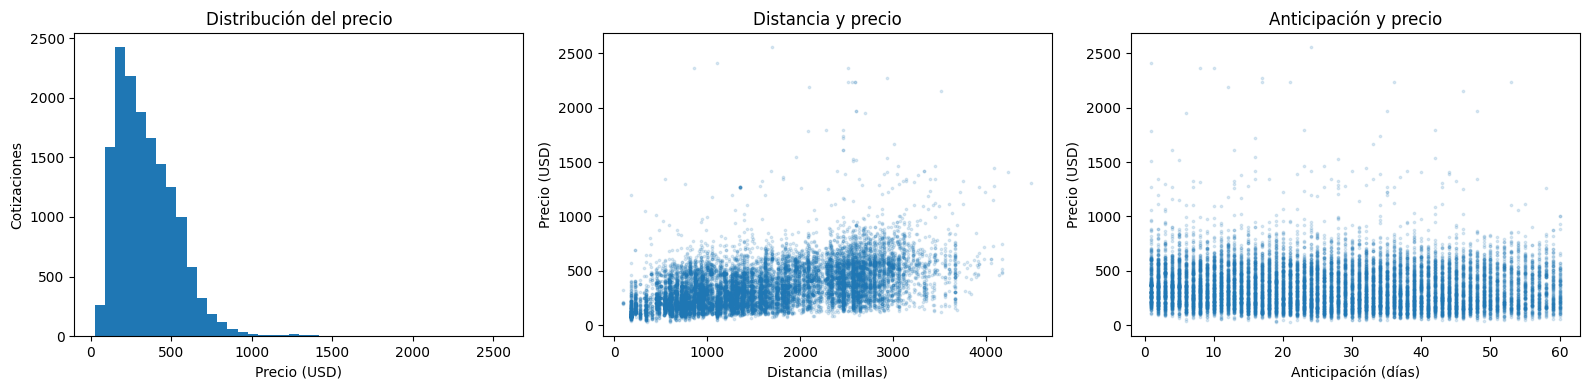

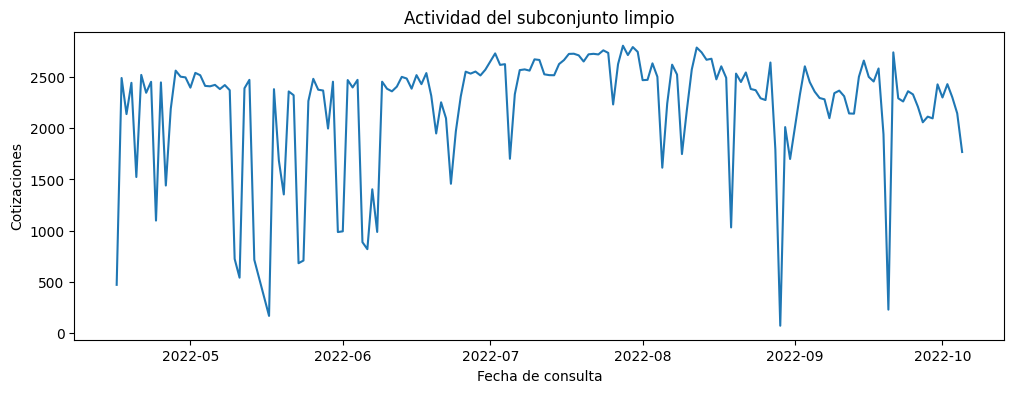

In [ ]:
fraccion = min(1.0, 15000 / TOTAL_CLEAN)
plot_pd = datos_modelo.sample(False, fraccion, seed=42).limit(20000).toPandas()
assert len(plot_pd) > 0
plot_pd.to_csv(OUT_DIR / 'tableau' / 'muestra_eda.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(plot_pd['fare_usd'], bins=40)
axes[0].set(xlabel='Precio (USD)', ylabel='Cotizaciones', title='Distribución del precio')
axes[1].scatter(plot_pd['distance_miles'], plot_pd['fare_usd'], s=3, alpha=0.15)
axes[1].set(xlabel='Distancia (millas)', ylabel='Precio (USD)', title='Distancia y precio')
axes[2].scatter(plot_pd['days_before'], plot_pd['fare_usd'], s=3, alpha=0.15)
axes[2].set(xlabel='Anticipación (días)', ylabel='Precio (USD)', title='Anticipación y precio')
plt.tight_layout()
fig.savefig(OUT_DIR / 'eda_variables.png', dpi=150, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pd.to_datetime(daily_pd['search_date']), daily_pd['quotes'])
ax.set(xlabel='Fecha de consulta', ylabel='Cotizaciones', title='Actividad del subconjunto limpio')
fig.savefig(OUT_DIR / 'eda_actividad.png', dpi=150, bbox_inches='tight')
plt.show()


### 3.3 · Visualizar las transformaciones
Comparo la distancia original y su logaritmo sobre las mismas filas para observar cómo se comprime la escala. También muestro la anticipación al cuadrado frente al precio. Una distribución más compacta no garantiza mejores predicciones: mantengo estas transformaciones como hipótesis y compruebo su utilidad con CV.


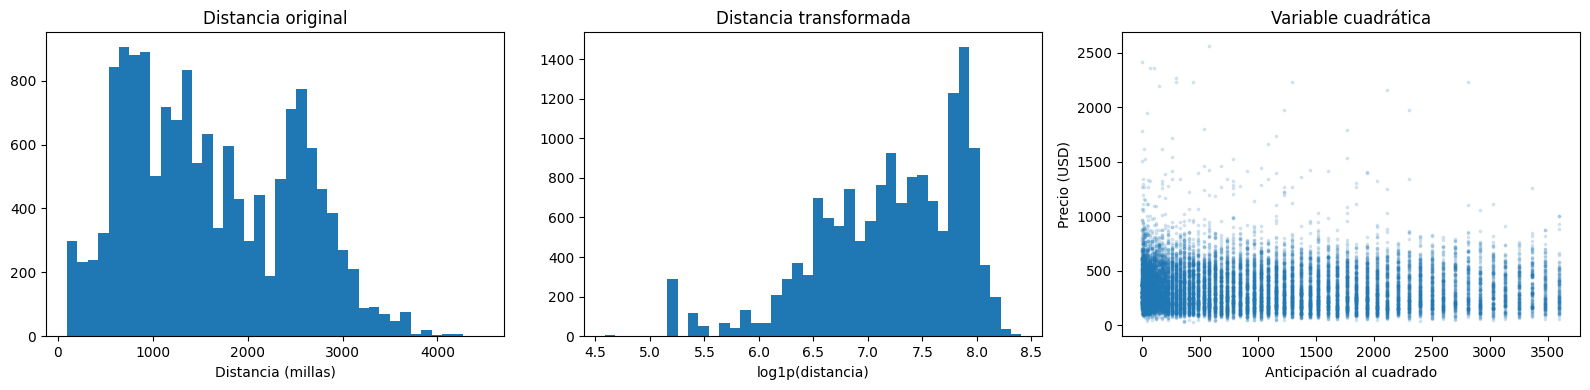

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(plot_pd['distance_miles'], bins=40)
axes[0].set(xlabel='Distancia (millas)', title='Distancia original')
axes[1].hist(plot_pd['log_distance'], bins=40)
axes[1].set(xlabel='log1p(distancia)', title='Distancia transformada')
axes[2].scatter(plot_pd['days_before_sq'], plot_pd['fare_usd'], s=3, alpha=0.15)
axes[2].set(xlabel='Anticipación al cuadrado', ylabel='Precio (USD)', title='Variable cuadrática')
plt.tight_layout()
fig.savefig(OUT_DIR / 'eda_transformaciones.png', dpi=150, bbox_inches='tight')
plt.show()


## Paso 4 · Preparar características y pipelines
### 4.1 · Codificar categorías sin imponerles un orden
Uso `StringIndexer` para identificar categorías y `OneHotEncoder` para representarlas como vectores. Así los índices de aerolíneas o aeropuertos no se interpretan como una escala numérica ordenada. `VectorAssembler` reúne categorías y cantidades en `features`; la etiqueta ya es numérica y no requiere indexador.

Incluyo estas etapas en cada pipeline para que las categorías se aprendan solo con su entrenamiento, evitando usar validación para preparar el modelo. `handleInvalid='keep'` permite procesar categorías nuevas. Los dos modelos ampliados comparten el mismo ensamblador, de modo que su comparación cambia el algoritmo y conserva las entradas.


In [ ]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

categorical_cols = ['origin', 'destination', 'airline', 'cabin']
numeric_cols = ['distance_miles', 'duration_min', 'days_before', 'stops']
label_col = 'fare_usd'

indexers = [
    StringIndexer(inputCol=c, outputCol=f'{c}_index', handleInvalid='keep')
    for c in categorical_cols
]
encoders = [
    OneHotEncoder(inputCol=f'{c}_index', outputCol=f'{c}_vec', handleInvalid='keep')
    for c in categorical_cols
]
assembler_inputs = [f'{c}_vec' for c in categorical_cols] + numeric_cols
assembler = VectorAssembler(inputCols=assembler_inputs, outputCol='features')


numeric_cols_transformadas = numeric_cols + ['log_distance', 'log_duration', 'days_before_sq']
route_indexer = StringIndexer(inputCol='route', outputCol='route_index', handleInvalid='keep')
route_encoder = OneHotEncoder(inputCol='route_index', outputCol='route_vec', handleInvalid='keep')
assembler_ruta = VectorAssembler(
    inputCols=[f'{c}_vec' for c in categorical_cols] + ['route_vec'] + numeric_cols_transformadas,
    outputCol='features'
)


### 4.2 · Elegir modelos y controlar su complejidad
La **regresión lineal base** ofrece una referencia sencilla. La versión ampliada permite comprobar si las transformaciones mejoran esa misma familia de modelo. Uso regularización para limitar coeficientes grandes, algo relevante al conservar variables originales junto a versiones relacionadas. Comparo `regParam` **0.01, 0.1 y 1.0** para probar tres intensidades; no son valores óptimos conocidos de antemano.

Elijo **Random Forest** como alternativa porque combina árboles capaces de aprender curvas e interacciones, por ejemplo, reglas distintas según ruta y anticipación. El promedio de árboles busca reducir la inestabilidad de un árbol individual. Uso `RandomForestRegressor` porque predigo una cantidad, a diferencia del clasificador de churn.

Pruebo profundidades **5, 8 y 10** para contrastar reglas generales con reglas más detalladas. Una profundidad baja puede quedarse corta; una mayor puede ajustar particularidades y aumentar tiempo o sobreajuste. La validación decidirá qué opción funciona mejor fuera de su entrenamiento. Fijo **50 árboles** para acotar el costo en Colab y variar solo la profundidad; no afirmo que sea el número óptimo. `seed=42` ayuda a reproducir el bosque. `pipeline.copy` cambia el parámetro probado sin reescribir las etapas.


In [ ]:
lr = LinearRegression(
    labelCol=label_col, featuresCol='features', regParam=0.01, maxIter=100
)
rf = RandomForestRegressor(
    labelCol=label_col, featuresCol='features', numTrees=50, maxDepth=5, seed=42
)

pipeline_base = Pipeline(stages=indexers + encoders + [assembler, lr])
pipeline_lineal_fe = Pipeline(
    stages=indexers + [route_indexer] + encoders + [route_encoder, assembler_ruta, lr]
)
pipeline_rf_fe = Pipeline(
    stages=indexers + [route_indexer] + encoders + [route_encoder, assembler_ruta, rf]
)
evaluator = RegressionEvaluator(
    labelCol=label_col, predictionCol='prediction', metricName='rmse'
)


## Paso 5 · Separar los datos por fecha
### 5.1 · Reservar un periodo posterior
Uso consultas anteriores a septiembre para desarrollo y reservo septiembre y los días disponibles de octubre para la comparación posterior. Esto permite evaluar cotizaciones de un periodo posterior al entrenamiento. Una separación aleatoria mezclaría fechas y respondería una pregunta distinta a predecir consultas futuras.

Separo por **fecha de consulta**, porque ese es el momento en que quiero estimar el precio. Un mismo vuelo puede aparecer cotizado en varios periodos; el objetivo incluye itinerarios ya observados. Como septiembre y octubre se revisaron en corridas anteriores, reporto esta nueva comparación como exploratoria, sin presentarla como una confirmación independiente.


In [ ]:
train_data = datos_modelo.filter(col('search_date') < '2022-09-01')
test_data = datos_modelo.filter(col('search_date') >= '2022-09-01')
TRAIN_ROWS = train_data.count()
TEST_ROWS = test_data.count()
assert TRAIN_ROWS > 0 and TEST_ROWS > 1
assert TRAIN_ROWS + TEST_ROWS == TOTAL_CLEAN
print('Desarrollo (antes de septiembre):', TRAIN_ROWS)
print('Prueba (septiembre y octubre):', TEST_ROWS)


Desarrollo (antes de septiembre): 301462
Prueba (septiembre y octubre): 78442


### 5.2 · Validación cruzada temporal con ventana expansiva
Una sola validación podría favorecer un modelo por las condiciones de un mes. Por eso evalúo cada candidato en tres periodos, ampliando el historial disponible y manteniendo el entrenamiento antes de su validación:

| Pliegue | Entrenamiento: fechas de consulta | Validación |
|---|---|---|
| 1 | Antes del 1 de junio | Junio |
| 2 | Antes del 1 de julio | Julio |
| 3 | Antes del 1 de agosto | Agosto |

Los límites mensuales facilitan interpretar cambios del error con el tiempo y dejan septiembre fuera de la selección. Uso filtros explícitos en lugar de pliegues aleatorios de `CrossValidator`, que permitirían entrenar con fechas posteriores a las evaluadas. Verifico que cada periodo tenga filas y que las fechas no se crucen.


In [ ]:
train_1 = train_data.filter(col('search_date') < '2022-06-01')
validation_1 = train_data.filter((col('search_date') >= '2022-06-01') & (col('search_date') < '2022-07-01'))

train_2 = train_data.filter(col('search_date') < '2022-07-01')
validation_2 = train_data.filter((col('search_date') >= '2022-07-01') & (col('search_date') < '2022-08-01'))

train_3 = train_data.filter(col('search_date') < '2022-08-01')
validation_3 = train_data.filter((col('search_date') >= '2022-08-01') & (col('search_date') < '2022-09-01'))

pliegues = [(train_1, validation_1), (train_2, validation_2), (train_3, validation_3)]
conteos_pliegues = []
for numero, (entrenamiento, validacion) in enumerate(pliegues, start=1):
    n_train = entrenamiento.count()
    n_val = validacion.count()
    assert n_train > 1 and n_val > 1, f'El pliegue {numero} necesita más datos.'
    ultima_fecha_train = entrenamiento.agg(F.max('search_date')).first()[0]
    primera_fecha_val = validacion.agg(F.min('search_date')).first()[0]
    assert ultima_fecha_train < primera_fecha_val
    conteos_pliegues.append({'pliegue': numero, 'filas_train': n_train, 'filas_validacion': n_val,
                            'ultima_fecha_train': ultima_fecha_train, 'primera_fecha_validacion': primera_fecha_val})

pliegues_pd = pd.DataFrame(conteos_pliegues)
pliegues_pd.to_csv(OUT_DIR / 'tableau' / 'particiones_cv.csv', index=False)
display(pliegues_pd)


,pliegue,filas_train,filas_validacion,ultima_fecha_train,primera_fecha_validacion
0,1,86428,63974,2022-05-31,2022-06-01
1,2,150402,80940,2022-06-30,2022-07-01
2,3,231342,70120,2022-07-31,2022-08-01


## Paso 6 · Comparar con validación cruzada temporal
### 6.1 · Entrenar los candidatos
Cada familia prueba tres candidatos sobre las mismas filas de cada pliegue: **nueve candidatos y 27 ajustes**. Mantengo una búsqueda pequeña para comparar alternativas con un costo viable en Colab. Los parámetros controlan aspectos distintos: regularización en las regresiones y profundidad en el bosque.

Cada `fit` reajusta el pipeline completo con el entrenamiento del pliegue; `transform` estima precios del mes siguiente. Guardo RMSE y tiempo para comparar calidad y costo. Un candidato debe funcionar en varios periodos, no solo ofrecer un buen resultado en un mes.


In [ ]:
candidatos = []
for regularizacion in [0.01, 0.1, 1.0]:
    candidatos.append({'configuracion': 'lineal_base', 'parametro': 'regParam',
        'valor_parametro': regularizacion,
        'pipeline': pipeline_base.copy({lr.regParam: regularizacion})})
    candidatos.append({'configuracion': 'lineal_fe', 'parametro': 'regParam',
        'valor_parametro': regularizacion,
        'pipeline': pipeline_lineal_fe.copy({lr.regParam: regularizacion})})

for profundidad in [5, 8, 10]:
    candidatos.append({'configuracion': 'random_forest_fe', 'parametro': 'maxDepth',
        'valor_parametro': profundidad,
        'pipeline': pipeline_rf_fe.copy({rf.maxDepth: profundidad})})

resultados_cv = []
for candidato in candidatos:
    for numero, (entrenamiento, validacion) in enumerate(pliegues, start=1):
        print(candidato['configuracion'], candidato['parametro'], candidato['valor_parametro'],
              '| Pliegue:', numero, flush=True)
        started = time.monotonic()
        modelo_actual = candidato['pipeline'].fit(entrenamiento)
        predicciones_validacion = modelo_actual.transform(validacion)
        error_cv = evaluator.evaluate(predicciones_validacion)
        resultados_cv.append({'configuracion': candidato['configuracion'],
            'parametro': candidato['parametro'], 'valor_parametro': candidato['valor_parametro'],
            'pliegue': numero, 'rmse': error_cv, 'segundos': time.monotonic() - started})

cv_pd = pd.DataFrame(resultados_cv)
assert len(cv_pd) == 27 and cv_pd['rmse'].notna().all()
assert (cv_pd['rmse'] < float('inf')).all()
assert not cv_pd.duplicated(['configuracion', 'parametro', 'valor_parametro', 'pliegue']).any()
cv_pd.to_csv(OUT_DIR / 'tableau' / 'validacion_cruzada_pliegues.csv', index=False)
display(cv_pd)


lineal_base regParam 0.01 | Pliegue: 1
lineal_base regParam 0.01 | Pliegue: 2
lineal_base regParam 0.01 | Pliegue: 3
lineal_fe regParam 0.01 | Pliegue: 1
lineal_fe regParam 0.01 | Pliegue: 2
lineal_fe regParam 0.01 | Pliegue: 3
lineal_base regParam 0.1 | Pliegue: 1
lineal_base regParam 0.1 | Pliegue: 2
lineal_base regParam 0.1 | Pliegue: 3
lineal_fe regParam 0.1 | Pliegue: 1
lineal_fe regParam 0.1 | Pliegue: 2
lineal_fe regParam 0.1 | Pliegue: 3
lineal_base regParam 1.0 | Pliegue: 1
lineal_base regParam 1.0 | Pliegue: 2
lineal_base regParam 1.0 | Pliegue: 3
lineal_fe regParam 1.0 | Pliegue: 1
lineal_fe regParam 1.0 | Pliegue: 2
lineal_fe regParam 1.0 | Pliegue: 3
random_forest_fe maxDepth 5 | Pliegue: 1
random_forest_fe maxDepth 5 | Pliegue: 2
random_forest_fe maxDepth 5 | Pliegue: 3
random_forest_fe maxDepth 8 | Pliegue: 1
random_forest_fe maxDepth 8 | Pliegue: 2
random_forest_fe maxDepth 8 | Pliegue: 3
random_forest_fe maxDepth 10 | Pliegue: 1
random_forest_fe maxDepth 10 | Pliegue: 

,configuracion,parametro,valor_parametro,pliegue,rmse,segundos
0,lineal_base,regParam,0.01,1,147.666228,19.553902
1,lineal_base,regParam,0.01,2,152.480326,16.047045
2,lineal_base,regParam,0.01,3,168.027214,17.481362
3,lineal_fe,regParam,0.01,1,142.967873,16.025808
4,lineal_fe,regParam,0.01,2,148.198749,18.571721
5,lineal_fe,regParam,0.01,3,164.812598,19.959869
6,lineal_base,regParam,0.10,1,147.668227,11.364314
7,lineal_base,regParam,0.10,2,152.464911,8.670727
8,lineal_base,regParam,0.10,3,168.007825,13.916532
9,lineal_fe,regParam,0.10,1,142.961611,12.763070


### 6.2 · Seleccionar por error en datos posteriores
Elijo **RMSE** porque se expresa en USD y penaliza más las equivocaciones grandes, importantes al estimar tarifas. Promedio los tres errores dando el mismo peso a cada mes para que el periodo con más filas no domine la selección. También conservo los resultados individuales para revisar estabilidad temporal.

La primera tabla muestra los nueve candidatos y la segunda el mejor de cada familia. Selecciono el menor promedio; si hay empate, uso nombre y luego menor valor del parámetro. La reducción porcentual se mide contra la mejor regresión base. El ganador se fija aquí, antes de evaluar septiembre y octubre, aunque otro modelo resulte mejor en esa comparación posterior.


,configuracion,parametro,valor_parametro,rmse_promedio
0,random_forest_fe,maxDepth,10.00,146.436763
1,random_forest_fe,maxDepth,8.00,149.474794
2,lineal_fe,regParam,1.00,151.960742
3,lineal_fe,regParam,0.10,151.990100
4,lineal_fe,regParam,0.01,151.993073
5,random_forest_fe,maxDepth,5.00,155.607840
6,lineal_base,regParam,1.00,155.942322
7,lineal_base,regParam,0.10,156.046988
8,lineal_base,regParam,0.01,156.057923


,configuracion,parametro,valor_parametro,rmse_promedio,reduccion_rmse_pct
0,random_forest_fe,maxDepth,10.0,146.436763,6.095561
2,lineal_fe,regParam,1.0,151.960742,2.553239
6,lineal_base,regParam,1.0,155.942322,0.000000


Elegido por CV: random_forest_fe | maxDepth = 10.0


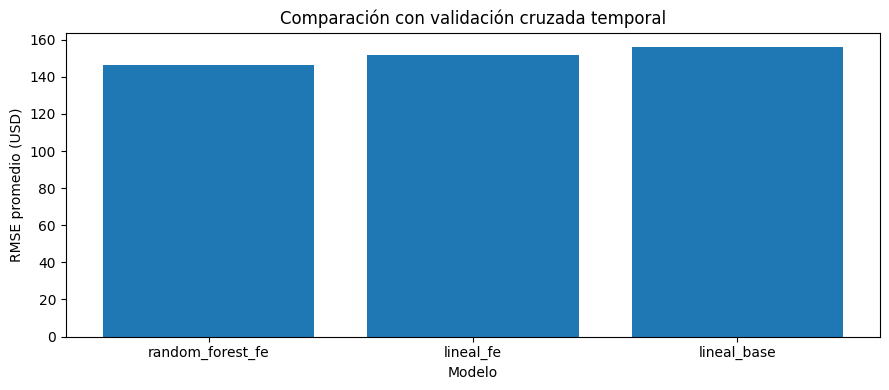

In [ ]:
comparacion = cv_pd.groupby(
    ['configuracion', 'parametro', 'valor_parametro'], as_index=False
)['rmse'].mean()
comparacion = comparacion.rename(columns={'rmse': 'rmse_promedio'})
comparacion = comparacion.sort_values(
    ['rmse_promedio', 'configuracion', 'valor_parametro']
).reset_index(drop=True)
comparacion.to_csv(OUT_DIR / 'tableau' / 'comparacion_validacion_cruzada.csv', index=False)
display(comparacion)

mejor_configuracion = comparacion.iloc[0]['configuracion']
mejor_parametro = comparacion.iloc[0]['parametro']
mejor_valor = float(comparacion.iloc[0]['valor_parametro'])
mejores_por_modelo = comparacion.drop_duplicates('configuracion').copy()
rmse_base_cv = float(mejores_por_modelo.loc[
    mejores_por_modelo['configuracion'] == 'lineal_base', 'rmse_promedio'].iloc[0])
mejores_por_modelo['reduccion_rmse_pct'] = (
    100 * (rmse_base_cv - mejores_por_modelo['rmse_promedio']) / rmse_base_cv
)
mejores_por_modelo.to_csv(OUT_DIR / 'tableau' / 'mejor_candidato_por_modelo.csv', index=False)
display(mejores_por_modelo)
print('Elegido por CV:', mejor_configuracion, '|', mejor_parametro, '=', mejor_valor)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(mejores_por_modelo['configuracion'], mejores_por_modelo['rmse_promedio'])
ax.set(xlabel='Modelo', ylabel='RMSE promedio (USD)', title='Comparación con validación cruzada temporal')
plt.tight_layout()
fig.savefig(OUT_DIR / 'comparacion_cv.png', dpi=150, bbox_inches='tight')
plt.show()


### 6.3 · Reentrenar los tres finalistas
Una vez elegidos los parámetros, entreno el mejor candidato de cada familia con **todo desarrollo**. Esto aprovecha también los meses usados como validación en CV, sin incorporar septiembre. Son tres ajustes finales. Guardo los tres para compararlos y conservo en `model` al ganador global de CV.

La media del precio de entrenamiento será una referencia constante: permite comprobar cuánto se gana frente a ignorar las características del vuelo. La calculo con desarrollo, no con los precios de prueba.


In [ ]:
modelos_finales = {}
for candidato in candidatos:
    fila = mejores_por_modelo.loc[
        mejores_por_modelo['configuracion'] == candidato['configuracion']
    ].iloc[0]
    if candidato['valor_parametro'] == float(fila['valor_parametro']):
        print('Entrenamiento final:', candidato['configuracion'], flush=True)
        modelos_finales[candidato['configuracion']] = candidato['pipeline'].fit(train_data)

assert len(modelos_finales) == 3
model = modelos_finales[mejor_configuracion]
media_entrenamiento = float(train_data.agg(F.avg('fare_usd')).first()[0])

# Describir las entradas del ganador para guardar su configuración.
if mejor_configuracion != 'lineal_base':
    numeric_cols = numeric_cols_transformadas
    categorical_cols = categorical_cols + ['route']

model.transform(train_data).select('origin', 'destination', 'features', 'fare_usd', 'prediction').show(5, truncate=False)


Entrenamiento final: lineal_base
Entrenamiento final: lineal_fe
Entrenamiento final: random_forest_fe
+------+-----------+-----------------------------------------------------------------------------------------------------------------------------------------+--------+-----------------+
|origin|destination|features                                                                                                                                 |fare_usd|prediction       |
+------+-----------+-----------------------------------------------------------------------------------------------------------------------------------------+--------+-----------------+
|LAX   |IAD        |(294,[0,31,38,47,100,287,288,289,290,291,292,293],[1.0,1.0,1.0,1.0,1.0,2679.0,683.0,42.0,1.0,7.893572073504902,6.52795791762255,1764.0]) |647.21  |518.9933311390689|
|SFO   |DFW        |(294,[3,21,34,47,176,287,288,289,291,292,293],[1.0,1.0,1.0,1.0,1.0,1468.0,216.0,42.0,7.292337176173877,5.37989735354046,1764.0])      

## Paso 7 · Comparación exploratoria en septiembre y octubre
### 7.1 · Evaluar los tres finalistas con las mismas métricas
Reporto los tres modelos sobre las mismas cotizaciones para que sus diferencias no se deban a particiones distintas. Uso métricas complementarias:

- **RMSE:** criterio de selección que da más peso a errores grandes, en USD.
- **MAE:** tamaño promedio del error absoluto, en USD, más directo para describir cuánto se desvía una estimación.
- **R²:** variación explicada respecto a una referencia constante basada en la media del conjunto evaluado; no es un porcentaje de predicciones correctas y puede ser negativo.

La comparación con la media de entrenamiento indica si el modelo aporta frente a una estimación constante. Cuento las predicciones negativas y conservo las tarifas altas: recortar resultados o quitar casos difíciles después de evaluar cambiaría lo que estoy midiendo. El ganador sigue siendo el elegido por CV. Conservo sus predicciones para estudiar los errores por grupos.


,configuracion,parametro,valor_parametro,filas_train,filas_test,rmse,mae,r2,predicciones_negativas,segundos_evaluacion,reduccion_rmse_vs_base_pct
0,lineal_base,regParam,1.0,301462,78442,157.444498,121.072468,0.265609,0,7.969124,0.000000
1,lineal_fe,regParam,1.0,301462,78442,153.538297,115.394951,0.301597,0,4.391969,2.481002
2,random_forest_fe,maxDepth,10.0,301462,78442,141.378397,109.829200,0.407841,0,10.845154,10.204295


El ganador permanece seleccionado por CV: random_forest_fe
RMSE de predecir la media de entrenamiento: 188.291 USD


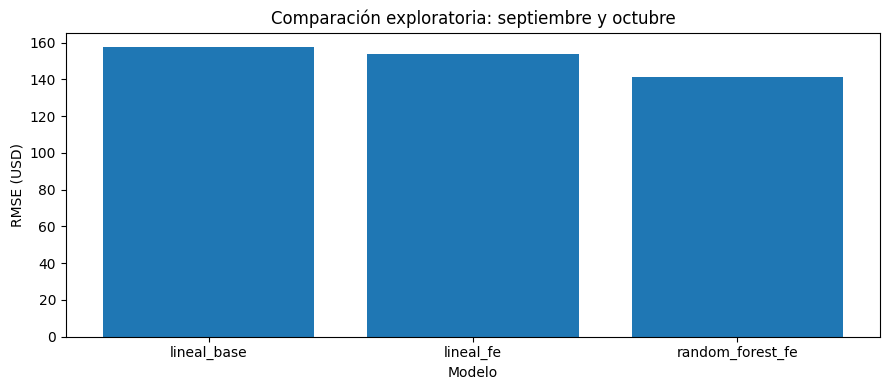

In [ ]:
resultados_prueba = []
for nombre, modelo_final in modelos_finales.items():
    started = time.monotonic()
    pred = modelo_final.transform(test_data).select(
        'search_date', 'flight_date', 'origin', 'destination', 'days_before', 'fare_usd', 'prediction'
    )
    pred = pred.withColumn('error_usd', col('prediction') - col('fare_usd'))
    pred = pred.withColumn('abs_error_usd', F.abs(col('error_usd')))
    pred = pred.withColumn('squared_error', col('error_usd') ** 2).cache()
    assert pred.filter(col('prediction').isNull() | F.isnan('prediction') |
                       (F.abs(col('prediction')) == float('inf'))).count() == 0
    fila = mejores_por_modelo.loc[mejores_por_modelo['configuracion'] == nombre].iloc[0]
    resultados_prueba.append({
        'configuracion': nombre, 'parametro': fila['parametro'],
        'valor_parametro': float(fila['valor_parametro']),
        'filas_train': TRAIN_ROWS, 'filas_test': TEST_ROWS,
        'rmse': evaluator.evaluate(pred),
        'mae': evaluator.copy({evaluator.metricName: 'mae'}).evaluate(pred),
        'r2': evaluator.copy({evaluator.metricName: 'r2'}).evaluate(pred),
        'predicciones_negativas': pred.filter(col('prediction') < 0).count(),
        'segundos_evaluacion': time.monotonic() - started
    })
    if nombre == mejor_configuracion:
        predictions = pred
    else:
        pred.unpersist()

comparacion_prueba = pd.DataFrame(resultados_prueba)
assert len(comparacion_prueba) == 3
referencia = test_data.withColumn('prediction', F.lit(media_entrenamiento))
rmse_media = evaluator.evaluate(referencia)
rmse_base_test = float(comparacion_prueba.loc[
    comparacion_prueba['configuracion'] == 'lineal_base', 'rmse'].iloc[0])
comparacion_prueba['reduccion_rmse_vs_base_pct'] = (
    100 * (rmse_base_test - comparacion_prueba['rmse']) / rmse_base_test
)
comparacion_prueba.to_csv(OUT_DIR / 'tableau' / 'comparacion_prueba.csv', index=False)
display(comparacion_prueba)

fila_ganadora = comparacion_prueba.loc[
    comparacion_prueba['configuracion'] == mejor_configuracion
].iloc[0]
rmse = float(fila_ganadora['rmse'])
mae = float(fila_ganadora['mae'])
r2 = float(fila_ganadora['r2'])
negativas = int(fila_ganadora['predicciones_negativas'])
reduccion_test_pct = float(fila_ganadora['reduccion_rmse_vs_base_pct'])
metricas_pd = comparacion_prueba.loc[
    comparacion_prueba['configuracion'] == mejor_configuracion
].copy()
metricas_pd['rmse_media_entrenamiento'] = rmse_media
metricas_pd.to_csv(OUT_DIR / 'tableau' / 'metricas_prueba.csv', index=False)
print('El ganador permanece seleccionado por CV:', mejor_configuracion)
print(f'RMSE de predecir la media de entrenamiento: {rmse_media:.3f} USD')

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(comparacion_prueba['configuracion'], comparacion_prueba['rmse'])
ax.set(xlabel='Modelo', ylabel='RMSE (USD)', title='Comparación exploratoria: septiembre y octubre')
plt.tight_layout()
fig.savefig(OUT_DIR / 'comparacion_prueba.png', dpi=150, bbox_inches='tight')
plt.show()


### 7.2 · Revisar dónde se equivoca el ganador
Agrupo el error por ruta y por anticipación para comprobar si el resultado global oculta segmentos más difíciles. Los rangos de menos de 7, 7–13, 14–29 y al menos 30 días facilitan comparar consultas cercanas y lejanas a la salida. Incluyo el conteo porque una métrica basada en pocas cotizaciones puede ser menos estable.

Estas tablas sirven para interpretar el alcance del modelo, no para eliminar después los grupos con mayor error. Las predicciones diarias permiten comparar la evolución del precio promedio observado y estimado.


In [ ]:
errores_ruta = predictions.groupBy('origin', 'destination').agg(
    F.count('*').alias('quotes'), F.avg('abs_error_usd').alias('mae_usd'),
    F.sqrt(F.avg('squared_error')).alias('rmse_usd')
)
errores_ruta.toPandas().to_csv(OUT_DIR / 'tableau' / 'errores_ruta.csv', index=False)

predictions = predictions.withColumn('anticipation_band',
    F.when(col('days_before') < 7, '01. <7 días')
     .when(col('days_before') < 14, '02. 7–13 días')
     .when(col('days_before') < 30, '03. 14–29 días')
     .otherwise('04. ≥30 días'))
errores_anticipacion = predictions.groupBy('anticipation_band').agg(
    F.count('*').alias('quotes'), F.avg('abs_error_usd').alias('mae_usd'),
    F.sqrt(F.avg('squared_error')).alias('rmse_usd')
).orderBy('anticipation_band')
error_pd = errores_anticipacion.toPandas()
error_pd.to_csv(OUT_DIR / 'tableau' / 'errores_anticipacion.csv', index=False)
display(error_pd)

predictions.groupBy('search_date').agg(
    F.count('*').alias('quotes'), F.avg('fare_usd').alias('actual_mean_usd'),
    F.avg('prediction').alias('predicted_mean_usd')
).orderBy('search_date').toPandas().to_csv(OUT_DIR / 'tableau' / 'predicciones_dia.csv', index=False)


,anticipation_band,quotes,mae_usd,rmse_usd
0,01. <7 días,11073,95.642430,131.247105
1,02. 7–13 días,12040,97.761604,129.063831
2,03. 14–29 días,26067,110.281198,140.173220
3,04. ≥30 días,29262,119.760227,150.683797


### 7.3 · Contrastar precio observado y estimado
La diagonal representa una estimación perfecta. Puntos debajo indican subestimación y puntos encima, sobreestimación; revisar las tarifas altas permite ver errores que un promedio puede ocultar. La gráfica usa una muestra para ser legible, mientras las métricas usan todo el conjunto de prueba.

No tomo el R² del taxímetro como meta para vuelos: aquel precio está ligado a una tarifa reglada, mientras aquí faltan factores comerciales que pueden afectar cada cotización.


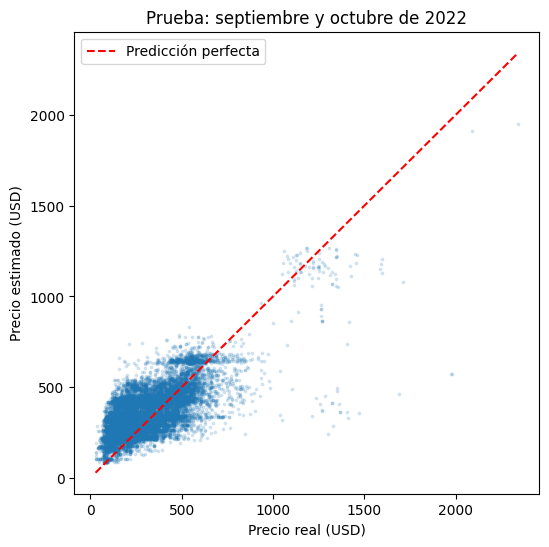

In [ ]:
scatter_pd = predictions.sample(False, min(1.0, 15000 / TEST_ROWS), seed=42).limit(20000).toPandas()
assert len(scatter_pd) > 0
scatter_pd.to_csv(OUT_DIR / 'tableau' / 'muestra_predicciones.csv', index=False)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(scatter_pd['fare_usd'], scatter_pd['prediction'], s=3, alpha=0.15)
lo = float(min(scatter_pd['fare_usd'].min(), scatter_pd['prediction'].min()))
hi = float(max(scatter_pd['fare_usd'].max(), scatter_pd['prediction'].max()))
ax.plot([lo, hi], [lo, hi], 'r--', label='Predicción perfecta')
ax.set(xlabel='Precio real (USD)', ylabel='Precio estimado (USD)', title='Prueba: septiembre y octubre de 2022')
ax.legend()
fig.savefig(OUT_DIR / 'real_vs_predicha.png', dpi=150, bbox_inches='tight')
plt.show()


## Paso 8 · Guardar el ganador y probar itinerarios nuevos
### 8.1 · Conservar el pipeline ajustado
Guardo el **ganador de CV** como `PipelineModel` para reutilizar la misma codificación de categorías y el mismo estimador sin entrenar otra vez. Guardar el pipeline completo evita preparar los datos nuevos con índices diferentes. Los CSV conservan las métricas de las otras dos familias para revisar la comparación.

Las transformaciones calculadas antes del pipeline se repiten con las mismas fórmulas al predecir. Mantengo nombres y unidades: millas, minutos, días, escalas y USD.


In [ ]:
MODEL_DIR = OUT_DIR / 'modelo'
local_model = LOCAL_ROOT / 'modelo_comparacion'
model.write().overwrite().save(str(local_model))
check_drive_budget(tree_bytes(local_model))
shutil.copytree(local_model, MODEL_DIR, dirs_exist_ok=True)
loaded_model = PipelineModel.load(str(MODEL_DIR))


### 8.2 · Cinco itinerarios hipotéticos
Uso ejemplos situados en 2022 para mostrar el funcionamiento dentro del contexto histórico del estudio. Calculo de nuevo anticipación, logaritmos, cuadrado y ruta; proporciono las escalas directamente porque ya conozco sus tramos.

La última fila incluye una aerolínea nueva para comprobar `handleInvalid='keep'`. Que el modelo acepte esa categoría no garantiza precisión en ella. Todas las entradas numéricas son obligatorias en esta versión. Estos ejemplos ilustran el uso del modelo; no miden su calidad porque no tienen un precio real observado.


In [ ]:
new_data = spark.createDataFrame([
    (1, '2022-09-01', '2022-09-08', 'JFK', 'LAX', 'AA', 'coach', 2475.0, 360.0, 0),
    (2, '2022-09-01', '2022-09-15', 'ATL', 'BOS', 'DL', 'coach', 946.0, 160.0, 0),
    (3, '2022-09-01', '2022-09-22', 'SFO', 'ORD', 'UA', 'coach', 1846.0, 255.0, 0),
    (4, '2022-09-01', '2022-09-03', 'MIA', 'SEA', 'AA', 'coach', 3000.0, 540.0, 1),
    (5, '2022-09-01', '2022-10-01', 'JFK', 'BOS', 'AEROLINEA_NUEVA', 'coach', 187.0, 80.0, 0)
], ['id', 'search_date', 'flight_date', 'origin', 'destination', 'airline', 'cabin',
    'distance_miles', 'duration_min', 'stops'])
new_data = new_data.withColumn('search_date', F.to_date('search_date'))
new_data = new_data.withColumn('flight_date', F.to_date('flight_date'))
new_data = new_data.withColumn('days_before', F.datediff('flight_date', 'search_date'))

# Mismas transformaciones deterministas que en entrenamiento.
new_data = new_data.withColumn('log_distance', F.log1p('distance_miles'))
new_data = new_data.withColumn('log_duration', F.log1p('duration_min'))
new_data = new_data.withColumn('days_before_sq', col('days_before') ** 2)
new_data = new_data.withColumn('route', F.concat_ws(' → ', 'origin', 'destination'))

new_predictions = loaded_model.transform(new_data)
new_pd = new_predictions.orderBy('id').select(
    'id', 'origin', 'destination', 'days_before', 'stops', 'prediction'
).toPandas()
assert len(new_pd) == 5 and new_pd['prediction'].notna().all()
new_pd.to_csv(OUT_DIR / 'tableau' / 'predicciones_nuevas.csv', index=False)
display(new_pd)


,id,origin,destination,days_before,stops,prediction
0,1,JFK,LAX,7,0,438.114020
1,2,ATL,BOS,14,0,246.452157
2,3,SFO,ORD,21,0,409.322261
3,4,MIA,SEA,2,1,414.094362
4,5,JFK,BOS,30,0,156.809243


### 8.3 · Comprobar que la recarga conserva las estimaciones
Comparo las cinco predicciones antes y después de guardar para verificar que la persistencia no cambia el resultado. Acepto una diferencia menor que `1e-8` por posibles variaciones numéricas. Uso `collect` solo porque son cinco filas; traer toda la fuente a Python no sería adecuado para su volumen.


In [ ]:
antes = model.transform(new_data).orderBy('id').select('prediction').collect()
despues = loaded_model.transform(new_data).orderBy('id').select('prediction').collect()
for i in range(5):
    assert abs(antes[i]['prediction'] - despues[i]['prediction']) < 1e-8
print('Comprobación correcta: el modelo recargado conserva las predicciones.')


Comprobación correcta: el modelo recargado conserva las predicciones.


### Conclusiones
La validación cruzada seleccionó **Random Forest con 50 árboles y profundidad máxima de 10**. Su RMSE promedio fue **146.44 USD**, frente a **151.96 USD** de la regresión ampliada y **155.94 USD** de la base: una reducción de **6.10 % respecto a base**. Entre las profundidades 5, 8 y 10, los errores fueron **155.61, 149.47 y 146.44 USD**. En estos pliegues, permitir reglas más detalladas ayudó; eso no demuestra que 10 sea la profundidad óptima fuera de los valores probados.

Después de reentrenar los tres finalistas con **301,462 cotizaciones anteriores a septiembre**, los evalué sobre las mismas **78,442 cotizaciones de septiembre y octubre**:

| Modelo | MAE (USD) | RMSE (USD) | R² |
|---|---:|---:|---:|
| Regresión lineal base | 121.07 | 157.44 | 0.2656 |
| Regresión lineal con feature engineering | 115.39 | 153.54 | 0.3016 |
| Random Forest con feature engineering | **109.83** | **141.38** | **0.4078** |

La mejora observada en CV también se mantuvo en este periodo: el bosque redujo el RMSE **10.20 % frente a base** y **7.92 % frente a la regresión ampliada**. Su MAE indica una desviación absoluta promedio de unos **109.83 USD**; el R² señala que explica aproximadamente **40.78 % de la variación del precio en prueba**, no que tenga ese porcentaje de predicciones correctas. También supera la referencia constante, cuyo RMSE fue **188.29 USD**.

El mayor MAE del ganador por anticipación se presentó en consultas de **30 días o más**, con **119.76 USD**. No hubo predicciones negativas. El modelo guardado conservó las cinco estimaciones después de recargarlo; esos ejemplos hipotéticos demuestran su uso, mientras las métricas anteriores evalúan su calidad con precios observados.

- **Enlace de Tableau Public:** https://public.tableau.com/app/profile/sebastian.osorio8789/viz/Preciosyactividaddevuelos2022SebastinOsorio_/Dashboard1

# Foto de dashboard de Tableau

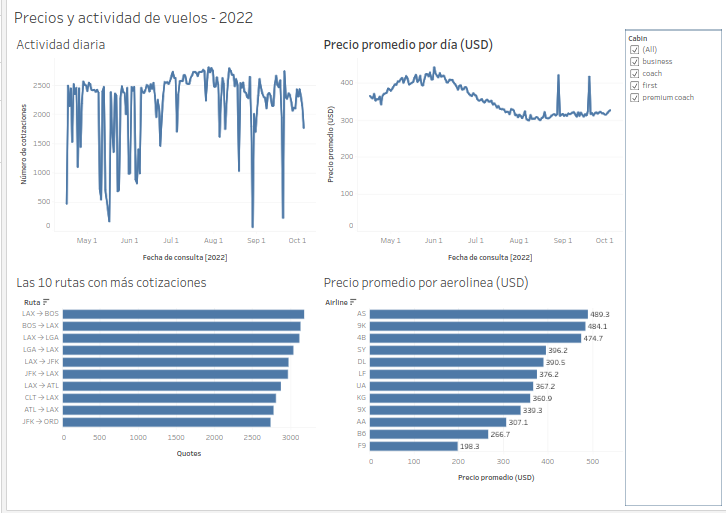